### this script investigate the author distribution across income groups over years

In [16]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.lines import Line2D

In [2]:
author_path="../../data/dropbox/LaborDivision/Data/deriveddata/pubs_noalpha_int/authors_noalpha_int.pkl"
pub_path="../../data/dropbox/LaborDivision/Data/deriveddata/pubs_noalpha_int/pubs_noalpha_int.pkl"
ingroup_path = '../../data/dropbox/LaborDivision/Data/additionaldata/cntry_classification/cntry_group_meta.csv'
info_path='../../data/dropbox/LaborDivision/Data/cleanedraw/author_info.pkl'

In [3]:
prop_author_path='../../data/dropbox/LaborDivision/figs/researcher_distribution/prop_author.pdf'
prop_author_new_exist_path='../../data/dropbox/LaborDivision/figs/researcher_distribution/prop_author_new_exist.pdf'

In [4]:
author_df=pd.read_pickle(author_path)
author_df.head()

,id,year,dis,cluster_id,role,Code
3,29768070,2008,51,20009795,F,JPN
4,29768070,2008,51,29411586,M,JPN
5,29768070,2008,51,37122561,M,CHN
6,29768070,2008,51,1221298,M,JPN
7,29768070,2008,51,38679117,L,JPN


In [5]:
pub_df=pd.read_pickle(pub_path)
pub_df.head()

,id,year,dis
2,38579297,2012,84
14,38579353,2012,132
27,38579408,2012,33
28,38579409,2012,12
37,38579425,2012,55


In [6]:
author_year=author_df[['cluster_id','year','Code']].drop_duplicates()
author_year.head()

,cluster_id,year,Code
3,20009795,2008,JPN
4,29411586,2008,JPN
5,37122561,2008,CHN
6,1221298,2008,JPN
7,38679117,2008,JPN


In [7]:
ingroup_df=pd.read_csv(ingroup_path)[['Code','ST']].drop_duplicates()
ingroup_df=ingroup_df.replace(to_replace={'ST':{'Others':'Lagging'}})
ingroup_df.head()

,Code,ST
0,AFG,Lagging
1,ALB,Lagging
2,DZA,Lagging
3,AND,Lagging
4,AGO,Lagging


In [8]:
author_year=author_year.merge(ingroup_df,on='Code')

In [9]:
year_income=author_year.groupby(['year','ST']).size().reset_index(name='count')

In [10]:
year_income=year_income.pivot(index='year',columns='ST',values='count')

In [11]:
year_income=year_income[['Advanced','Proficient','Developing','Lagging']]

In [12]:
year_income=year_income.div(year_income.sum(axis=1), axis=0)

In [14]:
year_income=year_income.reset_index().melt(id_vars='year',var_name='ST', value_name='value')

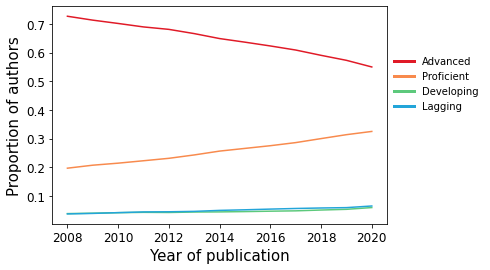

In [19]:
fig, ax=plt.subplots()
color={'Advanced':'#E01A27','Proficient':'#F88A4D','Developing':'#5DC97C','Lagging':'#23A5D9'}
sns.lineplot(x='year',y='value',hue='ST',data=year_income,palette=color,legend=False, ax=ax)
ax.tick_params(axis='both', labelsize=12)
ax.set_ylabel("Proportion of authors",fontsize=15)
ax.set_xlabel('Year of publication',fontsize=15)

colors = ['#E01A27', '#F88A4D', '#5DC97C','#23A5D9']
lines = [Line2D([0], [0], color=c, linewidth=3, linestyle='-') for c in colors]
labels = ['Advanced', 'Proficient', 'Developing','Lagging']
ax.legend(lines, labels,loc=(1.01,0.50),frameon=False)

plt.savefig(prop_author_path,bbox_inches='tight')

In [15]:
author_year.head()

,cluster_id,year,Code,ingroup_08-20
0,20009795,2008,JPN,H
1,29411586,2008,JPN,H
2,1221298,2008,JPN,H
3,38679117,2008,JPN,H
4,22736843,2008,JPN,H


In [20]:
info_df=pd.read_pickle(info_path)
info_df.head()

,cluster_id,yfp,npub,gender
0,689940,2008,1,unk
1,44823147,2008,1,unk
2,27676457,2011,1,M
3,59751143,2018,1,F
4,59894652,2004,8,M


In [21]:
author_year_yfp=author_year.merge(info_df,on='cluster_id',how='left')

In [22]:
author_year_yfp['new']=author_year_yfp.apply(lambda x: 1 if x.year==x.yfp else 0, axis=1)

In [23]:
year_new = author_year_yfp.groupby(['year','ST','new']).size().reset_index(name='count')

In [24]:
year_new = year_new.pivot_table(index='year',columns=['ST','new'],values='count')

In [25]:
year_new = year_new.div(year_new.sum(axis=1), axis=0)

In [26]:
year_new.columns=year_new.columns.from_tuples([(str(i), str(j)) for i, j in year_new.columns])
year_new.columns=year_new.columns.map(lambda x: ''.join(x) if isinstance(x, tuple) else x)

In [29]:
year_new

,Advanced0,Advanced1,Proficient0,Proficient1,Developing0,Developing1,Lagging0,Lagging1
year,,,,,,,,
2008,0.558624,0.168113,0.124604,0.072412,0.026984,0.011684,0.023126,0.014453
2009,0.555321,0.157811,0.131118,0.076325,0.028319,0.011780,0.024711,0.014615
2010,0.545383,0.156198,0.134386,0.080144,0.029707,0.012145,0.026705,0.015333
2011,0.533622,0.155863,0.138781,0.084164,0.031013,0.012030,0.028683,0.015843
2012,0.524802,0.156155,0.142043,0.089389,0.031170,0.011398,0.029887,0.015158
2013,0.512023,0.154198,0.145936,0.097252,0.032174,0.011983,0.031027,0.015408
2014,0.500067,0.148847,0.151679,0.104912,0.032997,0.011610,0.033068,0.016819
2015,0.490570,0.145778,0.156388,0.109604,0.033709,0.011995,0.035074,0.016881
2016,0.478733,0.144418,0.160365,0.115024,0.034639,0.012439,0.036746,0.017637


In [28]:
year_new=year_new[['Advanced0','Advanced1','Proficient0','Proficient1','Developing0','Developing1','Lagging0','Lagging1']]

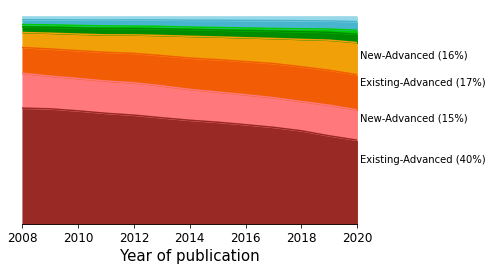

In [31]:
fig, ax = plt.subplots()
colors = ['#982924', '#FF787C', '#F25C05', '#F2A007', '#008C00', '#00CC00', '#48B5CF', '#96D8E8']
year_new.plot.area(ax=ax, stacked=True, color=colors,legend=False)
ax.spines['top'].set_visible(False)
ax.spines['left'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.set_yticks([])
ax.set_yticklabels([])
ax.set_xlabel('Year of publication',fontsize=15)
ax.set_xlim(2008,2020)
ax.tick_params(axis='both', labelsize=12)
plt.text(2020.1,0.3,'Existing-Advanced (40%)')
plt.text(2020.1,0.5,'New-Advanced (15%)')
plt.text(2020.1,0.67,'Existing-Advanced (17%)')
plt.text(2020.1,0.80,'New-Advanced (16%)')
plt.savefig(prop_author_new_exist_path,bbox_inches='tight')